# Fig 2B / 2C: ARI scores with Pretrained ResNet50 and ViT-S

Adapted from `embeddings_analysis/Fig_2BC_ARI_boxplot.ipynb`. Reads the yaml files written by
`experiments/resnet50/fig2b_ari.py` (batch effect) and `experiments/resnet50/fig2c_ari.py` (ALS:TIC).

In [1]:
import sys
from pathlib import Path

# Ensure project-root imports (e.g., utils.*) work regardless notebook launch directory.
for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (candidate / 'utils').is_dir():
        if str(candidate) not in sys.path:
            sys.path.append(str(candidate))
        break

import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
import yaml
from utils.config import load_env_paths
from utils.mypalette import day_palette, pairing_strategy_palette

ENV_PATHS = load_env_paths(str((candidate / 'configs' / 'env.yml').resolve()))

# Set of cells the ARIs were computed on (--annotations of fig2b_ari.py / fig2c_ari.py)
ANNOTATIONS = 'annotations_processed_crops'

fig_dir = os.path.join(ENV_PATHS['analysis_results_root_dir'], 'ARI_figures', ANNOTATIONS)
os.makedirs(fig_dir, exist_ok=True)

order = ['Hand-\ncrafted', 'uniDINO', 'CellPaint\nSSL', 'Pretrained\nViT-S', 'Pretrained\nResNet18',
         'SimCLR', 'SI\nSimCLR', 'Pretrained\nResNet50']

# Models added to the reference figure, their x labels are drawn in red
new_models = ['Pretrained\nViT-S', 'Pretrained\nResNet50']

# Colors of the reference figure, plus darker/lighter shades of the ResNet18 pink for the new models
model_palette = {
    'Hand-\ncrafted': pairing_strategy_palette['Hand-crafted'],
    'Pretrained\nResNet18': pairing_strategy_palette['Pretrained\nResNet18'],
    'Pretrained\nResNet50': '#a8467f',
    'Pretrained\nViT-S': '#f0b6d4',
    'SimCLR': pairing_strategy_palette['Standard SimCLR'],
    'uniDINO': pairing_strategy_palette['uniDINO'],
    'CellPaint\nSSL': pairing_strategy_palette['CellPaint SSL'],
    'SI\nSimCLR': pairing_strategy_palette['SI SimCLR'],
}
colors = [model_palette[m] for m in order]


def load_ari(results_subdir):
    with open(os.path.join(ENV_PATHS['analysis_results_root_dir'], results_subdir, ANNOTATIONS, 'best_umap_kmeans_ari.yaml'), 'r') as f:
        data = yaml.safe_load(f)

    # Flatten the nested structure
    rows = []
    for model_name, experiments in data.items():
        for exp_id, metrics in experiments.items():
            row = {'Model': model_name, 'Batch': exp_id}
            row.update(metrics)  # Merges ari, k_used, etc.
            rows.append(row)

    df = pd.DataFrame(rows)
    df['Model'] = df['Model'].replace({'hand-crafted': 'Hand-\ncrafted', 'CellPaint SSL': 'CellPaint\nSSL',
                                       'Standard\nSimCLR': 'SimCLR', 'Augmented\nSimCLR': 'SI\nSimCLR'})

    missing = set(order) - set(df['Model'])
    assert not missing, f'models missing from {results_subdir}: {missing}'
    return df


def highlight_new_models(ax):
    for label in ax.get_xticklabels():
        if label.get_text() in new_models:
            label.set_color('red')

## ARI Scores for batch (Fig 2B)

In [2]:
df_batch = load_ari('ARI_UMAP_batch')
df_batch.pivot(index='Model', columns='Batch', values='ari').loc[order].round(3)

Batch,all
Model,
Hand-\ncrafted,0.080
uniDINO,0.106
CellPaint\nSSL,0.038
Pretrained\nViT-S,0.204
Pretrained\nResNet18,0.145
SimCLR,0.120
SI\nSimCLR,0.379
Pretrained\nResNet50,0.164


In [3]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

# one ARI per model (all cells, K=4)
sns.barplot(x='Model', y='ari', data=df_batch, ax=ax, order=order, palette=colors)

# remove right and top spines
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.set_xlabel('')
ax.set_ylabel('ARI')
highlight_new_models(ax)
plt.title('Batch ARI')
plt.savefig(os.path.join(fig_dir, 'batch_ARI.pdf'), dpi=300, bbox_inches='tight')
plt.show()

<Figure size 800x600 with 1 Axes>

## ARI Scores for ALS:TIC (Fig 2C)

In [4]:
df_als = load_ari('ARI_UMAP')
df_als.pivot(index='Model', columns='Batch', values='ari').loc[order].round(3)

Batch,E1,E2,E3,E4
Model,,,,
Hand-\ncrafted,0.032,0.087,0.058,0.033
uniDINO,0.050,0.089,0.048,0.038
CellPaint\nSSL,0.046,0.018,0.009,0.006
Pretrained\nViT-S,0.140,0.128,0.250,0.066
Pretrained\nResNet18,0.112,0.125,0.111,0.064
SimCLR,0.074,0.083,0.165,0.046
SI\nSimCLR,0.194,0.224,0.678,0.113
Pretrained\nResNet50,0.112,0.112,0.148,0.063


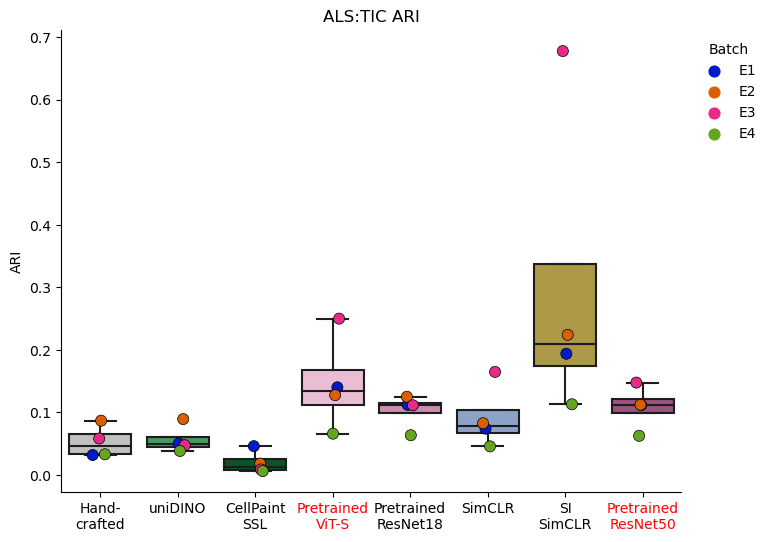

In [5]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

sns.boxplot(x='Model', y='ari', data=df_als, ax=ax, order=order, palette=colors, showfliers=False)

sns.stripplot(x='Model', y='ari', data=df_als, ax=ax, palette=day_palette, dodge=False,
              marker='o', alpha=1, hue='Batch', edgecolor='black', linewidth=0.5, size=8, order=order)
# remove right and top spines
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.set_xlabel('')
ax.set_ylabel('ARI')
highlight_new_models(ax)
ax.legend(title='Batch', bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False)
plt.title('ALS:TIC ARI')
plt.savefig(os.path.join(fig_dir, 'ALS_TIC_ARI.pdf'), dpi=300, bbox_inches='tight')
plt.show()